# Decoder ROC / AUC poster panels

ROC-curve + paired-probability panels for the respiration decoder, styled to match the SRNN
linear-probe poster figure (ROC with a recording-level bootstrap SEM band on the left, a paired
per-group predicted-probability scatter on the right).

**The modelling is unchanged.** Everything upstream of plotting is imported directly from
`poster-code/decoder_metrics_table.py` — the same `prepare()` (dataset, class filter, group
assignment), the same `feature_cols()` (raw BreathMetrics columns, <=40% missing, BORIS behavior
columns excluded), the same `make_models()` pipelines and hyper-parameters, and the same
leave-one-group-out CV (**valence -> leave-one-MOUSE-out**, **rank -> leave-one-CAGE-out**). So the
numbers here cannot drift from the bar-chart panel.

**One change was required.** A ROC needs a continuous score, and `SVC` has no `predict_proba`
unless it is fit with `probability=True`, so the SVM pipeline gets `model__probability=True`
(Platt scaling). This does **not** move the decision boundary — `SVC.predict()` still uses the
decision function — so balanced accuracy is identical to `decoder_metrics_table.py`; the parity
check below asserts that against `data/decoder_metrics_summary.csv`. The only caveat is that Platt
probabilities are fit by an internal CV on the training fold, so the SVM AUC is the AUC of the
*calibrated* score (in rare non-monotonic cases it can differ by a hair from a
`decision_function`-based AUC).

Everything else about the analysis — window type (`session` for both tasks, the best variant picked
by the bar-chart script), `class_weight="balanced"`, fixed untuned hyper-parameters, no separate
hold-out set — is carried over as-is.

**What gets drawn.** One ROC and one paired-probability figure per *task x model* (6 of each), so
any model can be dropped into the poster, plus one combined 2x2 A/B/C/D panel per model that
mirrors the reference layout (valence on top, rank on the bottom).

**Outputs** -> `poster-plots/decoder-roc/` (`.png` + `.svg`, transparent background) and
`data/decoder_roc_auc_summary.csv`.

> Needs numpy>=2 to unpickle the feature tables (same requirement as `decoder_metrics_table.py`).

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.base import clone
from sklearn.metrics import roc_curve, roc_auc_score, balanced_accuracy_score

# this notebook lives in poster-code/; everything else hangs off resp_classification/
HERE = os.path.abspath("")
RC = HERE if os.path.basename(HERE) == "resp_classification" else os.path.dirname(HERE)
sys.path.insert(0, os.path.join(RC, "poster-code"))

import decoder_metrics_table as dmt   # noqa: E402 -- single source of truth for the processing

DATA_DIR = os.path.join(RC, "data")
PLOT_DIR = os.path.join(RC, "poster-plots", "decoder-roc")
os.makedirs(PLOT_DIR, exist_ok=True)
print("resp_classification :", RC)
print("plots ->", PLOT_DIR)

resp_classification : C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification
plots -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc


## Style + per-task configuration

Colors come straight from `dmt.TASKS`, so these panels use the same palette as the existing poster
figures: valence teal `#53A1A9` (Positive) / pink `#A95376` (Negative), rank navy `#1C304F`
(Dominant) / mustard `#D5B032` (Subordinate). The *cohort* color that identifies a whole task in
the single-curve ROC panel is teal for valence and mustard for rank, matching the reference figure.

In [2]:
GRAY = dmt.GRAY

plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.transparent": True,     # transparent PNG/SVG for poster overlay
})

BIG = plt.rcParams["axes.labelsize"] * 1.65   # 1.65x axis labels + ticks, poster readability

# Window type per task: 'session' is the best variant for both (decoder_metrics_table picks it by
# highest mean balanced accuracy). Set to 'interaction' to render the sniff-bout variant instead.
WINDOW_TYPE = {"Valence": "session", "Rank": "session"}

PANEL = {
    "Valence": dict(
        cohort_color="#53A1A9",                  # teal = valence identity
        group_prefix="S", group_unit="mouse", group_units="mice", group_out="leave-one-mouse-out",
        pos_short="positive", title="Valence decodes from respiration",
        short_title="Valence decoder",
    ),
    "Rank": dict(
        cohort_color="#D5B032",                  # mustard = rank identity
        group_prefix="C", group_unit="cage", group_units="cages", group_out="leave-one-cage-out",
        pos_short="Dominant", title="Rank decode from respiration",
        short_title="Rank decoder",
    ),
}

# hi = class_order[0] (Positive / Dominant) = the ROC "positive" class; lo = class_order[1].
for task, p in PANEL.items():
    hi, lo = dmt.TASKS[task]["class_order"]
    pal = dmt.TASKS[task]["palette"]
    p["hi"] = dict(name=hi, color=pal[hi], label=hi)
    p["lo"] = dict(name=lo, color=pal[lo], label=lo)

MODELS = dmt.MODEL_ORDER          # ['LogReg', 'SVM', 'RandomForest']
N_BOOT = 1000                     # recording-level bootstrap draws for the ROC band
BOOT_SEED = 0

{t: (PANEL[t]["hi"]["name"], PANEL[t]["lo"]["name"]) for t in PANEL}

{'Valence': ('Positive', 'Negative'), 'Rank': ('Dominant', 'Subordinate')}

## Out-of-fold scores

Identical CV loop to `dmt.eval_dataset()` — same fold order, same `clone(model).fit(X[tr], y[tr])`.
It just additionally records `predict_proba` on the held-out windows, so every window ends up with
exactly one out-of-fold P(hi class), produced by a model that never saw its mouse/cage.

In [3]:
def make_models_proba():
    '''dmt.make_models() verbatim, with probability=True added to the SVC so it can emit a
    continuous score. The hyperplane (and therefore .predict) is unchanged.'''
    models = dmt.make_models()
    models["SVM"].set_params(model__probability=True)
    return models


def oof_scores(task, model_name, ds=None):
    '''Leave-one-group-out out-of-fold probabilities for one task x model.'''
    ds = ds or WINDOW_TYPE[task]
    df = dmt.prepare(task, ds)                 # same dataset / class filter / group column
    feats = dmt.feature_cols(df)               # same feature selection
    X, y, grp = df[feats], df["_y"].astype(str), df["_grp"].astype(str)
    hi = PANEL[task]["hi"]["name"]
    folds = sorted(grp.unique(), key=lambda g: (len(g), g))   # same fold order as dmt

    prob = np.full(len(df), np.nan)
    pred = np.array([None] * len(df), dtype=object)
    model = make_models_proba()[model_name]
    bal = []
    for g in folds:
        te = (grp == g).to_numpy(); tr = ~te
        if te.sum() == 0 or len(np.unique(y[tr])) < 2:
            continue
        m = clone(model).fit(X[tr], y[tr])
        prob[te] = m.predict_proba(X[te])[:, list(m.classes_).index(hi)]
        yp = m.predict(X[te]); pred[te] = yp
        bal.append(balanced_accuracy_score(y[te].to_numpy(), yp))

    return dict(
        task=task, ds=ds, model=model_name, hi=hi,
        y=y.to_numpy(), yhi=(y.to_numpy() == hi).astype(int), prob=prob, pred=pred,
        covered=~np.isnan(prob),
        rec=df["Trial"].astype(str).to_numpy(),      # one recording = one Trial
        grp=grp.to_numpy(), n_windows=len(df), n_features=len(feats),
        groups=sorted(grp.unique()), balacc_mean=float(np.mean(bal)), n_folds=len(bal),
    )


RES = {(t, m): oof_scores(t, m) for t in PANEL for m in MODELS}
print(f"computed {len(RES)} task x model out-of-fold score sets")

computed 6 task x model out-of-fold score sets


### Parity check

The balanced accuracy recomputed here must equal `data/decoder_metrics_summary.csv`, otherwise this
plotting notebook has drifted from the modelling script.

In [4]:
ref = pd.read_csv(os.path.join(DATA_DIR, "decoder_metrics_summary.csv"))
rows = []
for (task, mdl), r in RES.items():
    old = ref[(ref.task == task) & (ref.window_type == r["ds"]) & (ref.model == mdl)]
    orig = float(old["balacc_mean"].iloc[0]) if len(old) else np.nan
    rows.append({"task": task, "model": mdl, "window_type": r["ds"],
                 "balacc_here": round(r["balacc_mean"], 4), "balacc_metrics_csv": orig,
                 "match": bool(np.isclose(round(r["balacc_mean"], 4), orig, atol=5e-4))})
parity = pd.DataFrame(rows)
assert parity["match"].all(), parity[~parity["match"]]
print("all balanced accuracies match decoder_metrics_summary.csv")
parity

all balanced accuracies match decoder_metrics_summary.csv


,task,model,window_type,balacc_here,balacc_metrics_csv,match
0,Valence,LogReg,session,0.7912,0.7912,True
1,Valence,SVM,session,0.8068,0.8068,True
2,Valence,RandomForest,session,0.7968,0.7968,True
3,Rank,LogReg,session,0.4675,0.4675,True
4,Rank,SVM,session,0.4956,0.4956,True
5,Rank,RandomForest,session,0.5164,0.5164,True


## ROC + bootstrap band, and per-recording paired probabilities

The band is a **recording-level** bootstrap: resample recordings (the independent unit) with
replacement, pool their windows, recompute the ROC on a fixed FPR grid. The shaded band is +/-1 SD
of the bootstrap TPRs (= standard error of the ROC) and the AUC is reported +/- its bootstrap SE.
Bootstrapping recordings rather than windows keeps the band honest — window-level resampling would
ignore within-recording correlation and give a falsely tight band.

In [5]:
def roc_with_band(r, n_boot=N_BOOT, seed=BOOT_SEED):
    cov = r["covered"]
    y, s = r["yhi"][cov], r["prob"][cov]
    grid = np.linspace(0, 1, 101)
    fpr, tpr, _ = roc_curve(y, s)
    obs = np.interp(grid, fpr, tpr); obs[0] = 0.0
    auc = roc_auc_score(y, s)

    recs = np.unique(r["rec"][cov])
    rec_idx = {q: np.where((r["rec"] == q) & cov)[0] for q in recs}
    rng = np.random.RandomState(seed)
    boot_tpr, boot_auc = [], []
    for _ in range(n_boot):
        idx = np.concatenate([rec_idx[q] for q in rng.choice(recs, size=len(recs), replace=True)])
        yy, ss = r["yhi"][idx], r["prob"][idx]
        if len(np.unique(yy)) < 2:
            continue
        f, t, _ = roc_curve(yy, ss)
        ti = np.interp(grid, f, t); ti[0] = 0.0
        boot_tpr.append(ti); boot_auc.append(roc_auc_score(yy, ss))
    return dict(grid=grid, tpr=obs, se_tpr=np.asarray(boot_tpr).std(0),
                auc=float(auc), se_auc=float(np.std(boot_auc)), n_rec=len(recs))


def paired_info(r):
    '''One point per recording: (group, true class, mean out-of-fold P(hi class)).'''
    cov = r["covered"]
    out = []
    for q in np.unique(r["rec"][cov]):
        m = (r["rec"] == q) & cov
        out.append((str(r["grp"][m][0]), str(r["y"][m][0]), float(np.nanmean(r["prob"][m]))))
    return out


ROC = {k: roc_with_band(v) for k, v in RES.items()}
PAIRED = {k: paired_info(v) for k, v in RES.items()}

pd.DataFrame([{"task": t, "model": m, "AUC": round(ROC[(t, m)]["auc"], 3),
               "boot SE": round(ROC[(t, m)]["se_auc"], 3), "recordings": ROC[(t, m)]["n_rec"]}
              for t in PANEL for m in MODELS])

,task,model,AUC,boot SE,recordings
0,Valence,LogReg,0.847,0.019,16
1,Valence,SVM,0.889,0.021,16
2,Valence,RandomForest,0.862,0.028,16
3,Rank,LogReg,0.440,0.115,7
4,Rank,SVM,0.449,0.073,7
5,Rank,RandomForest,0.527,0.091,7


## Drawing

`draw_roc` / `draw_paired` render into an existing axes, so the same code produces both the
standalone per-model figures and the combined 2x2 panel.

In [6]:
def draw_roc(ax, task, model, title=None, legend_fs=12, label_fs=BIG, tick_fs=BIG):
    p, R = PANEL[task], ROC[(task, model)]
    ax.plot([0, 1], [0, 1], color=GRAY, ls=":", lw=1.2, label="chance")
    ax.fill_between(R["grid"], np.clip(R["tpr"] - R["se_tpr"], 0, 1),
                    np.clip(R["tpr"] + R["se_tpr"], 0, 1),
                    color=p["cohort_color"], alpha=0.22, linewidth=0)
    ax.plot(R["grid"], R["tpr"], color=p["cohort_color"], lw=2.8,
            label=f"AUC = {R['auc']:.2f} \u00b1 {R['se_auc']:.2f}")
    ax.set_xlabel("false positive rate", fontsize=label_fs)
    ax.set_ylabel("true positive rate", fontsize=label_fs)
    ax.tick_params(labelsize=tick_fs)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.set_xticks([0.0, 0.5, 1.0]); ax.set_yticks([0.00, 0.25, 0.50, 0.75, 1.00])
    ax.legend(fontsize=legend_fs, loc="lower right", frameon=False)
    if title:
        ax.set_title(title)
    return ax


def draw_paired(ax, task, model, title=None, s=70, legend_fs=8, label_fs=None, tick_fs=None,
                dx=0.0):
    '''One x position per held-out GROUP (mouse for valence, cage for rank). Each dot is one
    recording's mean out-of-fold P(hi class), colored by its TRUE class; the gray line links a
    group's two recordings to show the paired design. Dashed line = 0.5 decision boundary.
    (Rank cage 3 is a singleton -- one mouse, so one dot and no connector.)

    dx=0 keeps both dots on the group's x position, so the connector is exactly vertical. Set it
    to e.g. 0.07 to nudge the two classes apart when their probabilities are so close that one dot
    hides the other (the rank panels, where everything piles up on 0.5).'''
    p, info = PANEL[task], PAIRED[(task, model)]
    groups = sorted({g for g, _, _ in info})
    gx = {g: i for i, g in enumerate(groups)}
    off = {p["hi"]["name"]: -dx, p["lo"]["name"]: +dx}

    for g in groups:                                     # paired connectors
        pts = [(gx[g] + off[c], v) for gg, c, v in info if gg == g]
        if len(pts) == 2:
            ax.plot([pts[0][0], pts[1][0]], [pts[0][1], pts[1][1]],
                    color="#B7B7B7", lw=1.0, zorder=1)
    for spec in (p["hi"], p["lo"]):                      # dots, colored by true class
        xs = [gx[g] + off[spec["name"]] for g, c, _ in info if c == spec["name"]]
        ys = [v for _, c, v in info if c == spec["name"]]
        ax.scatter(xs, ys, s=s, color=spec["color"], edgecolor="white", linewidth=1.0,
                   zorder=3, label=spec["label"])
    ax.axhline(0.5, color=GRAY, ls="--", lw=1.0, zorder=2)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f"{p['group_prefix']}{i + 1}" for i in range(len(groups))])
    ax.set_xlim(-0.6, len(groups) - 0.4); ax.set_ylim(0, 1)
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_ylabel(f"predicted P({p['pos_short']})", fontsize=label_fs)
    if tick_fs:
        ax.tick_params(labelsize=tick_fs)
    ax.legend(fontsize=legend_fs, frameon=False, loc="upper center", ncol=2,
              bbox_to_anchor=(0.5, -0.16), handletextpad=0.3, columnspacing=1.0)
    if title:
        ax.set_title(title)
    return ax


def save_fig(fig, stem):
    for ext in ("png", "svg"):
        fig.savefig(os.path.join(PLOT_DIR, f"{stem}.{ext}"), transparent=True,
                    bbox_inches="tight", dpi=300)
    print("saved ->", os.path.join(PLOT_DIR, stem) + ".{png,svg}")

## Individual figures — one ROC and one paired scatter per task x model

In [7]:
for task in PANEL:
    for model in MODELS:
        p, r = PANEL[task], RES[(task, model)]
        stem = f"{task.lower()}_{model.lower()}"

        fig, ax = plt.subplots(figsize=(4.8, 4.6))
        draw_roc(ax, task, model,
                 title=f"{p['title']}\n{model} ROC ({p['group_out']}, "
                       f"n={len(r['groups'])} {p['group_units']})")
        save_fig(fig, f"{stem}_roc"); plt.close(fig)

        fig, ax = plt.subplots(figsize=(3.8, 3.6))
        draw_paired(ax, task, model, title=f"{p['short_title']} \u2014 {model}")
        fig.subplots_adjust(bottom=0.24, left=0.18, right=0.96, top=0.9)
        save_fig(fig, f"{stem}_paired"); plt.close(fig)

saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\valence_logreg_roc.{png,svg}


saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\valence_logreg_paired.{png,svg}


saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\valence_svm_roc.{png,svg}
saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\valence_svm_paired.{png,svg}


saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\valence_randomforest_roc.{png,svg}
saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\valence_randomforest_paired.{png,svg}


saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\rank_logreg_roc.{png,svg}
saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\rank_logreg_paired.{png,svg}


saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\rank_svm_roc.{png,svg}
saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\rank_svm_paired.{png,svg}


saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\rank_randomforest_roc.{png,svg}
saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\rank_randomforest_paired.{png,svg}


## Combined 2x2 panel per model

Reference layout: **A** valence ROC, **B** valence per-mouse probabilities, **C** rank ROC,
**D** rank per-cage probabilities.

saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\decoder_roc_panels_logreg.{png,svg}


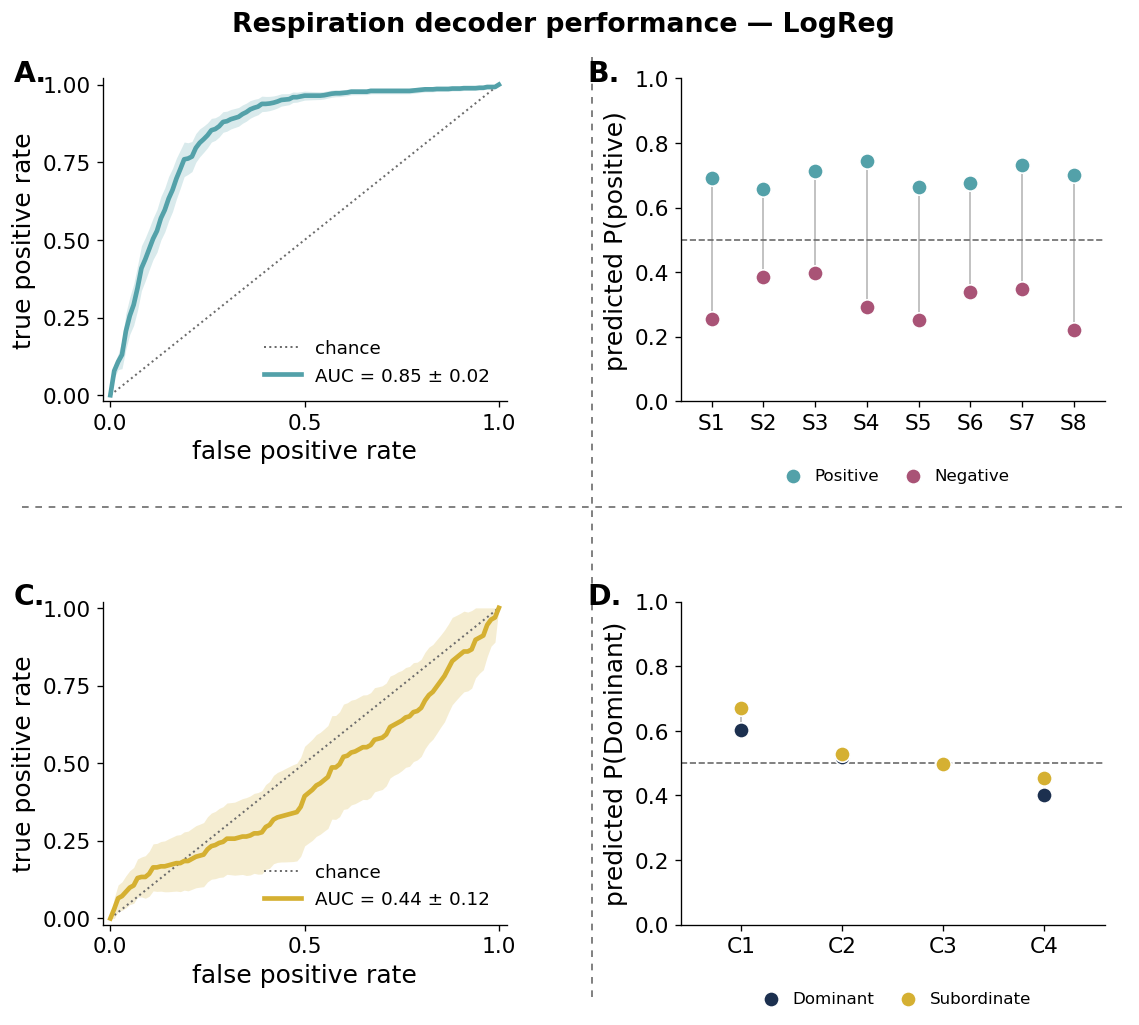

saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\decoder_roc_panels_svm.{png,svg}


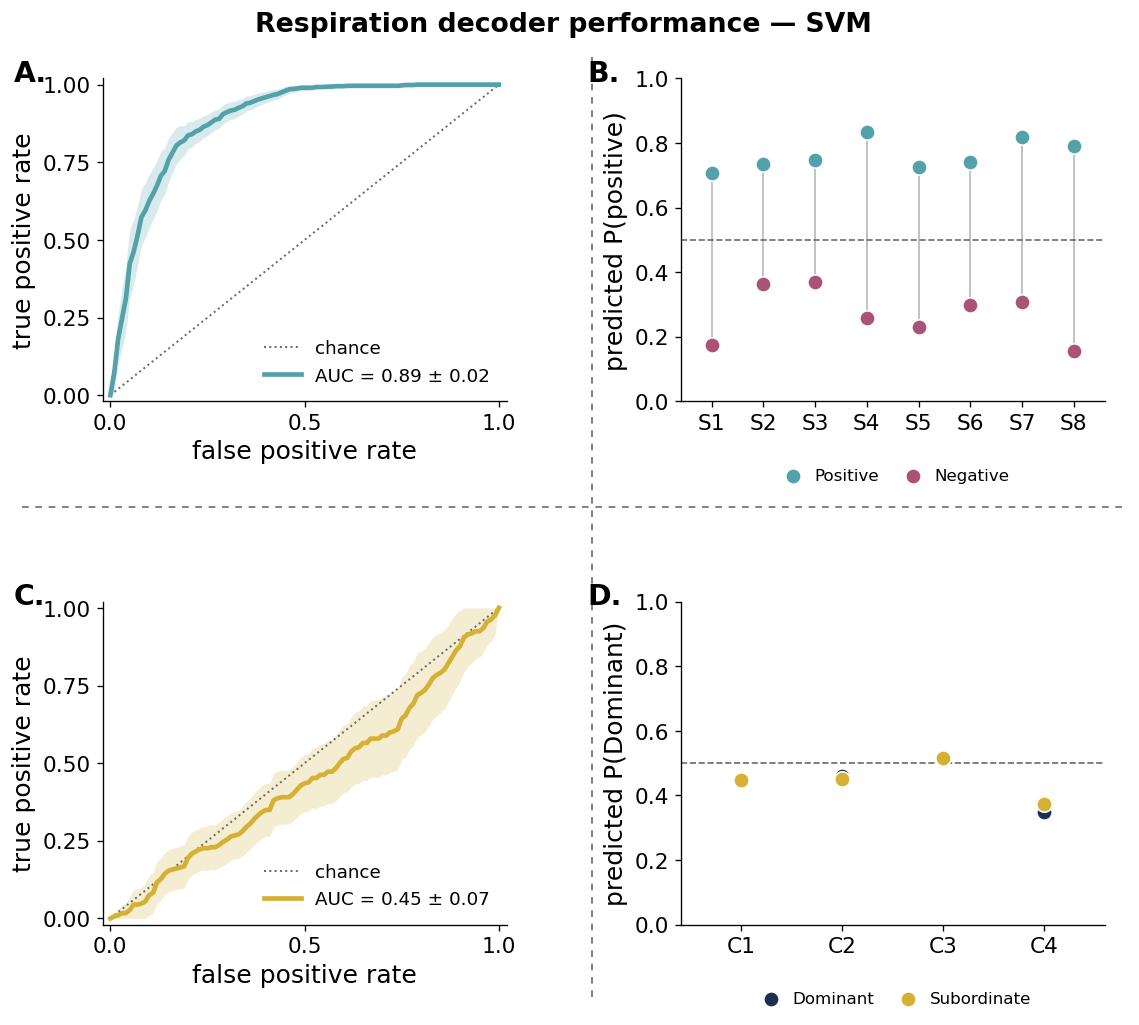

saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\decoder_roc_panels_randomforest.{png,svg}


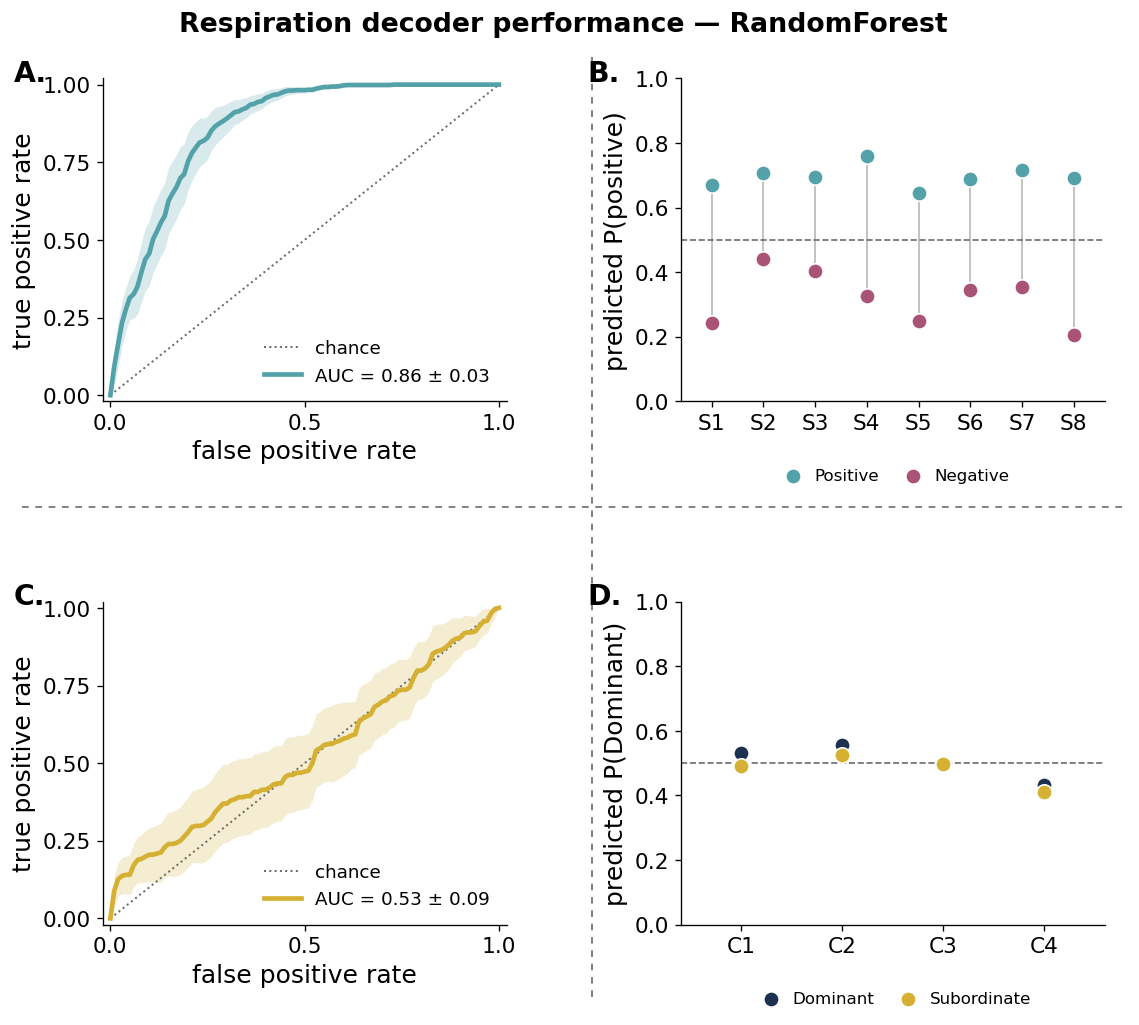

In [8]:
def panel_figure(model, suptitle=None):
    fig, axes = plt.subplots(2, 2, figsize=(9.6, 8.6),
                             gridspec_kw=dict(width_ratios=[1.0, 1.05]))
    for row, task in enumerate(("Valence", "Rank")):
        draw_roc(axes[row, 0], task, model, legend_fs=11, label_fs=15, tick_fs=13)
        draw_paired(axes[row, 1], task, model, s=85, legend_fs=10, label_fs=15, tick_fs=13)
    for ax, letter in zip(axes.ravel(), "ABCD"):
        ax.text(-0.22, 1.06, f"{letter}.", transform=ax.transAxes,
                fontsize=17, fontweight="bold", va="top", ha="left")

    fig.suptitle(suptitle or f"Respiration decoder performance \u2014 {model}",
                 fontsize=16, fontweight="bold", y=0.985)
    fig.subplots_adjust(left=0.10, right=0.97, top=0.92, bottom=0.10, wspace=0.42, hspace=0.62)
    # dotted dividers between the four quadrants, as in the reference figure
    dash = dict(color=GRAY, lw=1.0, ls=(0, (4, 4)), transform=fig.transFigure, zorder=0)
    fig.add_artist(Line2D([0.03, 0.99], [0.505, 0.505], **dash))
    fig.add_artist(Line2D([0.525, 0.525], [0.03, 0.945], **dash))
    return fig


for model in MODELS:
    fig = panel_figure(model)
    save_fig(fig, f"decoder_roc_panels_{model.lower()}")
    plt.show()

## AUC summary table

In [9]:
summary = pd.DataFrame([
    {"task": t, "window_type": RES[(t, m)]["ds"], "model": m,
     "positive_class": PANEL[t]["hi"]["name"], "cv": dmt.TASKS[t]["cv"],
     "n_windows": RES[(t, m)]["n_windows"], "n_features": RES[(t, m)]["n_features"],
     "n_groups": len(RES[(t, m)]["groups"]), "n_recordings": ROC[(t, m)]["n_rec"],
     "auc": round(ROC[(t, m)]["auc"], 4), "auc_boot_se": round(ROC[(t, m)]["se_auc"], 4),
     "balacc_mean": round(RES[(t, m)]["balacc_mean"], 4), "chance": 0.5}
    for t in PANEL for m in MODELS])
out_csv = os.path.join(DATA_DIR, "decoder_roc_auc_summary.csv")
summary.to_csv(out_csv, index=False)
print("saved ->", out_csv)
summary

saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\data\decoder_roc_auc_summary.csv


,task,window_type,model,positive_class,cv,n_windows,n_features,n_groups,n_recordings,auc,auc_boot_se,balacc_mean,chance
0,Valence,session,LogReg,Positive,LOSO (leave-one-mouse-out),1511,25,8,16,0.8475,0.0185,0.7912,0.5
1,Valence,session,SVM,Positive,LOSO (leave-one-mouse-out),1511,25,8,16,0.8886,0.0210,0.8068,0.5
2,Valence,session,RandomForest,Positive,LOSO (leave-one-mouse-out),1511,25,8,16,0.8617,0.0284,0.7968,0.5
3,Rank,session,LogReg,Dominant,LOCO (leave-one-cage-out),689,25,4,7,0.4398,0.1154,0.4675,0.5
4,Rank,session,SVM,Dominant,LOCO (leave-one-cage-out),689,25,4,7,0.4489,0.0733,0.4956,0.5
5,Rank,session,RandomForest,Dominant,LOCO (leave-one-cage-out),689,25,4,7,0.5273,0.0911,0.5164,0.5


## Folder notes

Written next to the figures so the folder documents itself, like
`poster-plots/decoder-metrics/NOTES.md` does.

In [10]:
NOTES = f"""# Decoder ROC / AUC panels — notes

Generated by `poster-code/decoder_roc_curves.ipynb`. All modelling is imported from
`poster-code/decoder_metrics_table.py`, so these panels and the bar-chart panels
(`poster-plots/decoder-metrics/`) are the same fits; see that folder's NOTES.md for the full
methodology and caveats.

## What is plotted

- **ROC** (`<task>_<model>_roc`): every window's **out-of-fold** P(positive class), pooled across
  folds — valence leave-one-mouse-out, rank leave-one-cage-out. The shaded band is +/-1 SD of a
  **recording-level** bootstrap (1000 draws, seed 0: resample recordings with replacement, pool
  their windows, recompute the ROC on a fixed FPR grid), and the AUC is +/- its bootstrap SE.
  Recordings, not windows, are the independent unit — bootstrapping windows would ignore
  within-recording correlation and give a falsely tight band.
- **Paired probabilities** (`<task>_<model>_paired`): one dot per recording = its mean out-of-fold
  P(positive class), placed at its held-out group's x position (S1..S8 = mice for valence,
  C1..C4 = cages for rank) and colored by its TRUE class, with a vertical gray line linking a
  group's two recordings. Dashed line = the 0.5 decision boundary. Where a group's two
  probabilities are nearly equal (rank, everything piled on 0.5) the dots overlap; `draw_paired`
  takes `dx` to nudge the classes apart if that ever needs separating.
- **Combined panels** (`decoder_roc_panels_<model>`): A valence ROC, B valence probabilities,
  C rank ROC, D rank probabilities.

One of each per model (LogReg / SVM / RandomForest), `.png` + `.svg`, transparent background.

## Numbers

{summary.to_string(index=False)}

Balanced accuracy is asserted equal to `data/decoder_metrics_summary.csv` in the notebook.
Full table: `data/decoder_roc_auc_summary.csv`.

## The one modelling change

`SVC` has no `predict_proba` unless fit with `probability=True`, so the SVM pipeline sets it (Platt
scaling). `SVC.predict()` still uses the decision function, so the decision boundary and balanced
accuracy are unchanged; only the SVM AUC is that of the *calibrated* score.

## Caveats

- Rank is at chance; cage 3 is a **singleton** (mouse 3_5, Subordinate only), so panel D shows one
  dot with no connector there and that CV fold is single-class.
- The ROC is a window-level curve; only the band and the AUC SE are computed over recordings.
"""
with open(os.path.join(PLOT_DIR, "NOTES.md"), "w", encoding="utf-8") as fh:
    fh.write(NOTES)
print("saved ->", os.path.join(PLOT_DIR, "NOTES.md"))

saved -> C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\poster-plots\decoder-roc\NOTES.md


## Reading these panels

- **Valence** is the real result: AUC ~0.85-0.89 depending on the model, and in panel B every
  mouse's positive-interaction recording sits above its negative one (the gray connector never
  crosses), i.e. the decoder generalizes to a mouse it never trained on.
- **Rank** is at chance (AUC ~0.44-0.53, balanced accuracy ~0.47-0.52) and the panel-D dots cluster
  on the 0.5 line — consistent with the bar chart and with the caveat in
  `poster-plots/decoder-metrics/NOTES.md`. Cage 3 is a singleton (mouse 3_5, Subordinate only), so
  it contributes one dot and no connector, and its CV fold is single-class.
- The ROC pools every out-of-fold window, so it is a *window-level* curve; the bootstrap band and
  the AUC SE are computed over **recordings**, which is the honest unit of independence here.